# Chapter 3: Don't Trust It Yet: Checks Before You Read a Result

This notebook runs every piece of code in the chapter, in order, with the chapter's text around it. Read the chapter on the site: [Don't Trust It Yet: Checks Before You Read a Result](https://books.sugiv.fyi/lift/trust-checks.html). Everything is simulated from seeded code in `sim/`, so a run gives the same numbers as the book.

In [1]:
# Run this cell first. In Google Colab it fetches the companion repo; anywhere else, run the
# notebook from a clone of it. Either way it moves to the repo's root so `sim` can be imported.
import os
import pathlib
import sys

if "google.colab" in sys.modules:
    if not pathlib.Path("/content/lift-not-luck").exists():
        !git clone -q --depth 1 https://github.com/sugix/lift-not-luck /content/lift-not-luck
    %pip install -q pingouin
candidates = [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path("/content/lift-not-luck")]
root = next(p for p in candidates if (p / "sim" / "parlo.py").is_file())
os.chdir(root)
sys.path.insert(0, str(root))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg
from scipy import stats
def glue(name, value, display=True):
    """In the book, glue() puts a computed number into the text. Here the numbers are already
    written into the text, so it only shows the value when asked to."""
    if display:
        from IPython.display import display as show
        show(value)

from sim import design as D, trust as T, style

style.apply()
pd.set_option("display.precision", 3)


def glue_num(name, value):
    glue(name, float(value), display=False)


S = T.streak_test()
logged = S[S.logged]
lm = logged.groupby("arm").retained.mean()
am = S.groupby("arm").retained.mean()
glue_num("dash_lift", 100 * (lm["shield"] - lm["control"]))
glue_num("itt_lift", 100 * (am["shield"] - am["control"]))
glue_num("n_missing", (~S.logged).sum())
glue_num("missing_pct", 100 * (~S.logged).sum() / (S.arm == "shield").sum())

Here's the finding first. Parlo reran the Streak Shield test at the size Chapter 2 asked for, and it came back looking great: **+2.3 points of day-30 retention**, clearly significant. But 591 learners, about 4% of the shield arm, never made it into the analysis table. The screen that introduces the shield on day 8 crashed on old Android phones before the exposure event was logged. Those learners were less engaged than average, so losing them flattered the shield. Counted properly, the lift is **1.6 points**.

Nothing about the result looked wrong. The p-value was small, the confidence interval was tidy, the effect was plausible. The only clue was that the two arms were slightly different sizes. This chapter is about the checks that catch problems like that *before* anyone reads the result, and about two agent-specific traps, retries and caches, that break Juno experiments in the same quiet way.

> **Note**
>
> The numbers come from `lift/sim/trust.py`. It reuses Chapter 1's learners and adds two bugs: a crash in the Streak Shield introduction screen, and a retry and cache setup in the Juno test. Real bugs are less tidy, but they hide in exactly these places.

## Check 1: are the arms the size you asked for?

The test asked for a 50/50 split. Here's what reached the analysis table:

In [3]:
counts = logged.arm.value_counts().sort_index()
srm = stats.chisquare(counts.values)          # expected: equal counts
print(counts.to_dict(), f"  share in shield arm: {counts['shield'] / counts.sum():.1%}")
print(f"sample ratio mismatch p-value: {srm.pvalue:.1e}")

{'control': 15733, 'shield': 15076}   share in shield arm: 48.9%
sample ratio mismatch p-value: 1.8e-04


In [4]:
glue_num("srm_p", srm.pvalue)
glue_num("shield_share", 100 * counts["shield"] / counts.sum())

A 48.9% share looks fine to the eye. It isn't. With 30,000 learners, a fair coin almost never lands that far from 50%, and the chi-square test says so: a p-value of 0.0002. That's a **sample ratio mismatch (SRM)**, and it's the single most useful check in experimentation (Fabijan et al., 2019). The rule is blunt: **if the SRM check fails, don't read the result.** Find the cause first.

Why so strict? Because an SRM means learners went missing, or got added, for a reason connected to the arm they were in. Learners who disappear for a reason are almost never a random sample. Here, the missing learners are exactly the ones who would have dragged the shield arm down.

### Finding the cause: split the check by segment

An overall SRM tells you *something* is wrong. Running the same check inside segments tells you *where*. Pingouin's chi-square test of independence asks whether the platform mix differs between arms, which it shouldn't if the coin was fair:

In [5]:
print(pd.crosstab(logged.platform, logged.arm))
_, _, chi = pg.chi2_independence(logged, x="platform", y="arm")
chi.loc[chi.test == "pearson", ["chi2", "dof", "pval"]]

arm          control  shield
platform                    
old Android     1982    1383
other          13751   13693


,chi2,dof,pval
0,92.43,1.0,6.975e-22


Old Android learners are badly under-represented in the shield arm. That's the crash, found in two lines. The same habit works for any segment you log: country, app version, browser, sign-up channel. When an SRM appears, the segment where it's concentrated usually names the bug.

### The fix, and how much it mattered

The fix for the analysis is to count every learner who was **assigned**, using the assignment log rather than the exposure log, with outcomes from the warehouse. This is called **intention to treat**. It answers "what happens if we launch?", and launching would also crash on old Android phones. (The fix for the product is to fix the crash.)

One test is one draw, so here's the same comparison averaged over 150 reruns:

In [6]:
rows = []
for s in range(150):
    s_ = T.streak_test(seed=100 + s)
    lg = s_[s_.logged]
    m, a = lg.groupby("arm").retained.mean(), s_.groupby("arm").retained.mean()
    old = lg[lg.platform == "old Android"].arm.value_counts().values
    rows.append({"logged learners only": 100 * (m["shield"] - m["control"]),
                 "everyone assigned (ITT)": 100 * (a["shield"] - a["control"]),
                 "true effect": 100 * s_.true_effect.mean(),
                 "overall SRM p < 0.001": stats.chisquare(lg.arm.value_counts().values).pvalue < 0.001,
                 "old Android SRM p < 0.001": stats.chisquare(old).pvalue < 0.001})
reruns = pd.DataFrame(rows)
reruns.mean().to_frame("average over 150 reruns").round(2)

,average over 150 reruns
logged learners only,2.30
everyone assigned (ITT),1.56
true effect,1.53
overall SRM p < 0.001,0.55
old Android SRM p < 0.001,1.00


In [7]:
rm = reruns.mean()
glue_num("rr_logged", rm["logged learners only"])
glue_num("rr_itt", rm["everyone assigned (ITT)"])
glue_num("rr_catch", 100 * rm["overall SRM p < 0.001"])
glue_num("rr_catch_seg", 100 * rm["old Android SRM p < 0.001"])

On average the logged-only comparison says 2.3 points and intention to treat says 1.6, right on the truth. On average, the bug adds about half again to the lift.

The last two rows are the uncomfortable part. Using the usual strict threshold of p < 0.001, the overall SRM check catches this bug in only 55% of reruns: losing 4% of one arm is near the edge of what 30,000 learners can reveal. This test happened to be caught; nearly half of its reruns wouldn't be. The same check inside the old Android segment catches it 100% of the time. **Run the SRM check by segment, not just overall.** Most experimentation platforms do this automatically; if you've built your own, add it.

## Check 2: does the pipeline cry wolf?

An SRM check tests the *split*. An **A/A test** tests the whole pipeline: assignment, logging, metric code and statistics. Give both arms the identical experience, run the full analysis, and see whether it reports a difference. Do that many times (it's cheap on historical data: shuffle real learners into fake arms) and the p-values should be spread evenly between 0 and 1. About 5% fall below 0.05, about 5% fall between 0.05 and 0.10, and so on.

Here's that for two pipelines from Chapter 2: Juno's completion rate analysed per learner (correct) and per lesson (the bug).

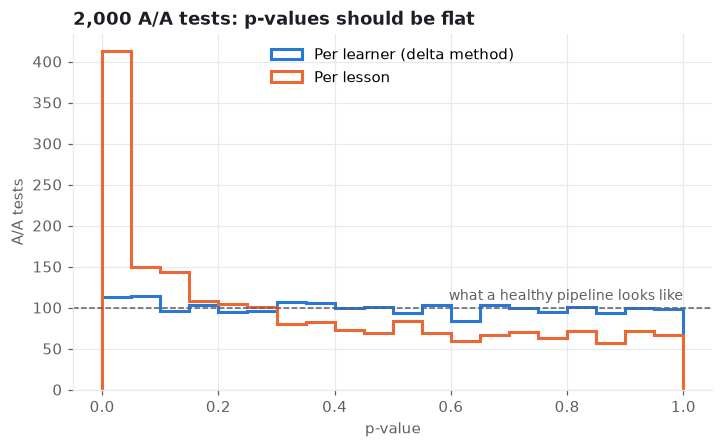

In [8]:
lx, ly = D.juno_learners(2_000, 0.78, reps=2_000, seed=0)
rx, ry = D.juno_learners(2_000, 0.78, reps=2_000, seed=1)
pvals = {}
for name, fn in [("Per learner (delta method)", D.delta_ratio), ("Per lesson", D.naive_ratio)]:
    a, sa = fn(lx, ly)
    b, sb = fn(rx, ry)
    pvals[name] = 2 * stats.norm.sf(np.abs(a - b) / np.hypot(sa, sb))

fig, ax = plt.subplots()
bins = np.linspace(0, 1, 21)
for (name, p), colour in zip(pvals.items(), [style.SERIES[0], style.SERIES[1]]):
    ax.hist(p, bins=bins, histtype="step", linewidth=2, color=colour, label=name)
ax.axhline(len(p) / 20, color=style.MUTED, linewidth=1, linestyle="--")
ax.annotate("what a healthy pipeline looks like", xy=(1, len(p) / 20), xytext=(0, 5),
            textcoords="offset points", ha="right", fontsize=9, color=style.MUTED)
ax.set(title="2,000 A/A tests: p-values should be flat",
       xlabel="p-value", ylabel="A/A tests")
ax.legend(loc="upper center")
plt.show()

In [9]:
glue_num("aa_low", 100 * (pvals["Per lesson"] < 0.05).mean())

The per-learner p-values are flat, as they should be. The per-lesson ones pile up near zero: 21% of identical comparisons come out "significant". You'd never see this from a single experiment. You see it immediately from a few hundred A/A tests.

I run A/A tests at three moments: when a new metric is added, when the assignment or logging code changes, and continuously as a small always-on A/A experiment. That last one is cheap insurance: if it ever fails its SRM check or starts producing small p-values, something in the platform broke.

## Check 3: one learner, one arm

The coin has to be flipped for the thing you randomise, and stay flipped. Parlo tested a new lesson screen, and the assignment code bucketed by **device id**, which was the identifier the app already had. Most learners use one device. About 30% use two, typically a phone and a tablet, and each device flipped its own coin. Here's one run:

In [10]:
dev = T.two_devices(assign_by="device")
print(f"learners who saw both versions: {dev.saw_both.mean():.0%} of everyone, "
      f"{dev.saw_both[dev.two_devices].mean():.0%} of two-device learners")

learners who saw both versions: 15% of everyone, 50% of two-device learners


In [11]:
def device_reruns(by, reps=200):
    out = []
    for s in range(reps):
        d = T.two_devices(assign_by=by, seed=1_000 + s)
        g = d.groupby("arm").lessons.mean()
        out.append(g["treatment"] / g["control"] - 1)
    return np.array(out)


dev_by_device, dev_by_learner = device_reruns("device"), device_reruns("learner")
glue_num("both_share", 100 * dev.saw_both.mean())
glue_num("dev_device", 100 * dev_by_device.mean())
glue_num("dev_learner", 100 * dev_by_learner.mean())
glue_num("dev_true", 100 * T.DEVICE_LIFT)
glue_num("dev_dilution", 100 * (1 - dev_by_device.mean() / dev_by_learner.mean()))

Half of the two-device learners, 15% of everyone, saw *both* versions. The logs file each of them under whichever device they used first, so the "treatment" arm contains learners who spent half their time on the old screen, and the "control" arm contains learners who spent half their time on the new one. Averaged over 200 reruns, bucketing by device estimates a lift of 4.8% when the new screen truly adds 6%. Bucketing by learner gets 6.0%. About 20% of the effect leaked away, and it's the *heaviest* learners who leak, because two-device learners study more.

This doesn't show up in a sample ratio check: the arms are still 50/50. The check that catches it is direct: **count learners who appear in both arms.** It should be zero. Three habits keep it there:

- **Randomise on the most stable identity you have**: a learner id once they log in, not a device or cookie.
- **Decide what happens before login.** Logged-out sessions get a device-level coin; once the learner logs in, keep the arm they already saw or exclude those sessions, but write the rule down.
- **For agents, the same applies to conversations.** If a prompt version is chosen per conversation, a learner who opens three chats may meet three versions of Juno. Assign per learner unless you deliberately want per-conversation randomisation, and then analyse per conversation with the learner as a cluster.

## Juno: retries and the shared cache

Agent systems have two extra ways to break an experiment, and Juno's team hit both in one test. Prompt **v2** (Juno's team calls every candidate prompt v2 until it ships; this isn't Chapter 1's) is more thorough than v1 and truly lifts lesson completion by 4 points. Learners are randomised 50/50, 4,000 per arm. The logging records one row per **session**, meaning one call to the model.

In [12]:
J = T.juno_test()
summary = J.groupby("arm").agg(learners=("learner", "nunique"), sessions=("lesson", "size"),
                               completion_per_session=("completed", "mean"))
summary

,learners,sessions,completion_per_session
arm,,,
v1,4000,20074,0.729
v2,4000,20831,0.726


In [13]:
glue_num("j_sess_p", stats.chisquare(summary.sessions.values).pvalue)
glue_num("j_v1", 100 * summary.completion_per_session["v1"])
glue_num("j_v2", 100 * summary.completion_per_session["v2"])

The dashboard says v2 is no better, slightly worse even: 72.6% against 72.9% completion per session. And there's a clue in the counts. Learners are balanced, but sessions aren't: an SRM test on sessions gives p = 0.0002.

**Retries.** v2 is slower, so more of its calls time out, and Juno's orchestrator automatically retries. Each attempt is logged as a new session, and the timed-out attempt counts as incomplete. So v2 gets extra sessions, many of them recorded as failures that the learner never saw as failures. The unit was wrong again, as in Chapter 2: the experiment randomised learners, so the analysis should count lessons per learner, with each lesson's *final* attempt.

In [14]:
attempts = J.groupby("lesson").attempt.max()
print(f"retried lessons: {(attempts > 1).groupby(J.groupby('lesson').arm.first()).mean().round(3).to_dict()}")
d, lo, hi = T.delta_diff(T.per_learner(J))
print(f"v2 - v1, per lesson (final attempt), per learner: {100 * d:+.1f} points, 95% CI {100 * lo:+.1f} to {100 * hi:+.1f}")

retried lessons: {'v1': 0.012, 'v2': 0.048}
v2 - v1, per lesson (final attempt), per learner: +2.4 points, 95% CI +1.1 to +3.7


In [15]:
glue_num("j_dedup", 100 * d)
served_v2 = (J[J.arm == "v2"].groupby("lesson").served.first() == "v2").mean()
glue_num("j_served", 100 * served_v2)

Now v2 is ahead by 2.4 points. Better, but still short of the true 4. The rest went to the **cache**.

Juno caches answers to common questions, keyed by the question text. The cache is shared by both arms, so when a v2 learner asks something a v1 learner asked earlier, they get v1's cached answer. A quick **exposure check** shows it, by asking which prompt actually produced each answer a v2 learner saw:

In [16]:
J[J.arm == "v2"].groupby("lesson").served.first().value_counts(normalize=True).round(3)

served
v2    0.6
v1    0.4
Name: proportion, dtype: float64

Only 60% of v2 lessons were actually served by v2. The experiment compared v1 against a blend that was only partly v2, so the effect shrank in proportion. Here's the same test with the prompt version added to the cache key:

In [17]:
fixed = T.juno_test(shared_cache=False)
d2, lo2, hi2 = T.delta_diff(T.per_learner(fixed))
print(f"v2 - v1 with separate caches: {100 * d2:+.1f} points, 95% CI {100 * lo2:+.1f} to {100 * hi2:+.1f}")

v2 - v1 with separate caches: +3.7 points, 95% CI +2.4 to +5.0


In [18]:
glue_num("j_fixed", 100 * d2)

3.7 points, consistent with the true 4. Neither bug was in the statistics. Both were in the plumbing, and both pushed toward "v2 doesn't help", which is how good agent changes get abandoned.

Caches aren't the only thing that leaks between arms in agent systems. Anything shared does: conversation memory, retrieved documents written by the other arm, tool results stored for reuse, a fine-tuning loop trained on both arms' transcripts. Ask of each one: *can a learner in one arm receive something produced by the other arm?*

## The checklist

Before I read any result, these get a yes:

| Check | How | What it catches |
|---|---|---|
| **Sample ratio**, overall and by segment | Chi-square on counts per arm | Crashes, redirects, bot filters, logging that depends on the arm |
| **A/A health** | Flat p-values on shuffled historical data | Wrong unit of analysis, broken metric code |
| **Right unit** | Count the unit you randomised (learners), not events | Retries, multiple sessions, heavy users dominating |
| **Exposure** | Did each arm actually receive its version? | Shared caches, memory, stale clients, feature flags overridden |
| **Assignment consistency** | Each learner in exactly one arm, for the whole test | Device-level bucketing, logged-out users, ID changes |
| **Pre-period balance** | Arms look alike *before* the test started | Bad randomisation; also the input to CUPED (Chapter 5) |

None of these say whether the change worked. They say whether the experiment can tell you.

> **In the wild**
>
> Fabijan and colleagues (Fabijan et al., 2019) studied sample ratio mismatches across experiments at Microsoft and Booking.com and found them common enough to check automatically on every test. The causes they catalogue are mundane: bots filtered differently in each arm, redirects that only the treatment performs, crashes in one browser, telemetry lost on slow connections. Each one quietly removes a non-random slice of one arm, exactly like Streak Shield's crash.

## Pitfalls

- **Ignoring a "small" SRM.** A 51/49 split on 30,000 learners isn't small; it's a bug. Don't read the result until you've found it.
- **Checking SRM only overall.** Segment-level checks catch bugs that hide in a slice of traffic.
- **Analysing exposed learners when exposure depends on the arm.** If the treatment can stop someone from being logged, analyse everyone assigned.
- **Counting attempts as outcomes.** For agents, retries, fallbacks and regenerations multiply rows unevenly between arms.
- **Shared state between arms.** Caches, memory and shared retrieval stores turn your treatment into a blend.

## Exercises

1. **Bigger crash.** Set `CRASH_RATE` to 0.6 in `sim/trust.py`. How does the SRM p-value change? How does the bias change? Is a bigger SRM always a bigger bias?
2. **A harmless SRM?** Change `streak_test` so the crash hits learners *at random*, regardless of platform. Is the logged-only estimate still biased? Would you still refuse to read the result? (I would: you can't know it was random until you've found the cause.)
3. **Retry rate as a guardrail.** v2's retry rate is four times v1's. Turn that into a latency guardrail: what retry rate would you tolerate, and how many learners do you need to test it? (Chapter 2's non-inferiority recipe applies.)
4. **Your own A/A.** Take any table of users with a metric, shuffle them into two fake arms 1,000 times, and plot the p-values. Is your metric code healthy?

## Further reading

Fabijan and colleagues (Fabijan et al., 2019) catalogue the causes of sample ratio mismatch seen across thousands of experiments at Microsoft and Booking.com. Kohavi, Tang and Xu (Kohavi et al., 2020) cover A/A tests, SRM and other trustworthiness checks in depth.